# Mini Project: Classification Algorithms Exploration

## Team Model: Support Vector Machine (SVM)


## Introduction:
Social media has a dual impact on students, offering helpful academic resources while also creating severe risks to focus, mental health, and daily routines. In this project, we will build a classification model to analyze how digital engagement shapes daily life and well-being. The project will include an EDA of the dataset and a trained SVM model.

## Problem definition:
Social media affects students differently and there is no simple way to tell which students are negatively impacted. This project aims to predict a student’s Overall_Impact using an SVM classifier, and compare its performance against Logistic Regression.

## Dataset:
We are working on the "Impact of Social Media on Life" dataset of 4,500 student entries with 16 attributes found on Kaggle. Our target is the Overall_Impact column.

**Dataset link:** https://www.kaggle.com/datasets/harishyadav0506/impact-of-social-media-on-life


## Algorithm explanation:

### What is the algorithm?
A Support Vector Machine (SVM) is a supervised machine-learning model that uses support vectors and optionally kernel functions to handle nonlinear data in order to classify data by identifying the best hyperplane that maximizes the margin between classes.


### How does the algorithm work?
SVM works by finding an optimal decision boundary, called a hyperplane, that maximizes the distance (margin) between different classes of data.

### When should this algorithm be used?
SVM preferably used when you have high-dimensional, clean datasets with fewer samples than features, or when the decision boundary is highly non-linear. Moreover, SVM is highly effective when training data must fit into limited memory.

### Advantages:
* High-Dimensional Power
* Memory Efficient
* Versatile Boundaries
* Robust to Overfitting

### Limitations:
* Sensitive to Noise
* Scales Poorly
* No Direct Probabilities; calculating them requires expensive cross-validation
* Complex Tuning
* Black Box Nature; hard to interpret visually


## Project sections:
* Data cleaning section
* EDA section
* Data preprocessing
* Model training / testing
* Model Evaluation
* Compare SVM with Logistic Regrassion

## Team Members:
* Tarfah Alsunaidi
* Wasan Alkhaldi
* Lujain Al Ibrahim
* Muhannad Alshamrani

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


### Data Understanding

In [ ]:
df = pd.read_csv("Social_media_impact_on_life.csv")
print(df.shape)

df.head()

(4500, 16)


,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   object 
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   object 
 3   Academic_Level               4500 non-null   object 
 4   Primary_Platform             4500 non-null   object 
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   object 
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   object 
 12  Perceived_Stress_Score       4454 non-null   float64
 13  Mental_Health_Inde

In [ ]:
df.describe()

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
count,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4454.000000,4500.000000,4415.000000
mean,18.703333,5.295933,1.796844,6.701333,2.472000,13.512124,79.873111,3.429282
std,1.981182,2.604497,0.699245,1.189998,1.030484,7.072859,12.876044,0.392662
min,15.000000,0.900000,0.000000,3.000000,1.000000,0.000000,32.000000,1.900000
25%,17.000000,3.400000,1.300000,6.000000,2.000000,9.000000,72.000000,3.200000
50%,19.000000,4.700000,1.800000,6.800000,3.000000,13.000000,82.000000,3.460000
75%,20.000000,6.600000,2.300000,7.500000,3.000000,18.000000,89.000000,3.720000
max,26.000000,14.000000,4.500000,10.500000,5.000000,40.000000,98.000000,4.000000


### Checking & Cleaning

In [ ]:
print((df.isnull().sum() / len(df)) * 100 )
print(df.isnull().sum() )


Student_ID                     0.000000
Age                            0.000000
Gender                         0.000000
Academic_Level                 0.000000
Primary_Platform               0.000000
Daily_Usage_Hours              0.000000
Weekend_Extra_Hours            0.000000
Device_Type                    0.000000
Sleep_Duration_Hours           0.000000
Sleep_Quality_Score            0.000000
Late_Night_Usage               0.000000
Social_Comparison_Frequency    0.000000
Perceived_Stress_Score         1.022222
Mental_Health_Index            0.000000
Academic_Performance_GPA       1.888889
Overall_Impact                 0.000000
dtype: float64
Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Primary_Platform                0
Daily_Usage_Hours               0
Weekend_Extra_Hours             0
Device_Type                     0
Sleep_Duration_Hours            0
Sleep_Quality_Score             0
Late_

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df = df.dropna()
print((df.isnull().sum() / len(df)) * 100 )
df.shape

Student_ID                     0.0
Age                            0.0
Gender                         0.0
Academic_Level                 0.0
Primary_Platform               0.0
Daily_Usage_Hours              0.0
Weekend_Extra_Hours            0.0
Device_Type                    0.0
Sleep_Duration_Hours           0.0
Sleep_Quality_Score            0.0
Late_Night_Usage               0.0
Social_Comparison_Frequency    0.0
Perceived_Stress_Score         0.0
Mental_Health_Index            0.0
Academic_Performance_GPA       0.0
Overall_Impact                 0.0
dtype: float64


(4369, 16)

There are no duplicate samples. Two columns contain missin values less than 2% so we decided to drop these rows.

In [ ]:
df.describe()

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
count,4369.000000,4369.000000,4369.000000,4369.000000,4369.000000,4369.000000,4369.000000,4369.000000
mean,18.703136,5.302014,1.796384,6.698901,2.471046,13.529183,79.817578,3.429680
std,1.980096,2.608300,0.697976,1.188141,1.028952,7.068291,12.872718,0.392935
min,15.000000,0.900000,0.000000,3.000000,1.000000,0.000000,32.000000,1.900000
25%,17.000000,3.400000,1.300000,6.000000,2.000000,9.000000,72.000000,3.200000
50%,19.000000,4.700000,1.800000,6.800000,3.000000,13.000000,82.000000,3.470000
75%,20.000000,6.600000,2.300000,7.500000,3.000000,18.000000,89.000000,3.720000
max,26.000000,14.000000,4.500000,10.500000,5.000000,40.000000,98.000000,4.000000


In [ ]:
#To make sure no invalid age values is included.
df=df.drop(df[df["Age"]<0].index)

In [ ]:
df["Age"].value_counts()

,count
Age,
18,995
19,879
17,700
20,612
21,341
16,330
22,174
15,157
23,83


In [ ]:
num=["Age","Daily_Usage_Hours","Weekend_Extra_Hours","Sleep_Duration_Hours","Perceived_Stress_Score","Mental_Health_Index","Academic_Performance_GPA"]
q1=df[num].quantile(0.25)
q3=df[num].quantile(0.75)
iqr=q3-q1
lb=q1-iqr*1.5
hb=q3+iqr*1.5
outliers=(df[num]<lb) | (df[num]>hb)
outliers.count()

,0
Age,4369
Daily_Usage_Hours,4369
Weekend_Extra_Hours,4369
Sleep_Duration_Hours,4369
Perceived_Stress_Score,4369
Mental_Health_Index,4369
Academic_Performance_GPA,4369


In [ ]:
df.shape

(4369, 16)

by using the IQR Method we were able to determine that there are no outliers within the data. indicating that the values are assigned correctly

### Univariante

Text(0.5, 1.0, 'After')

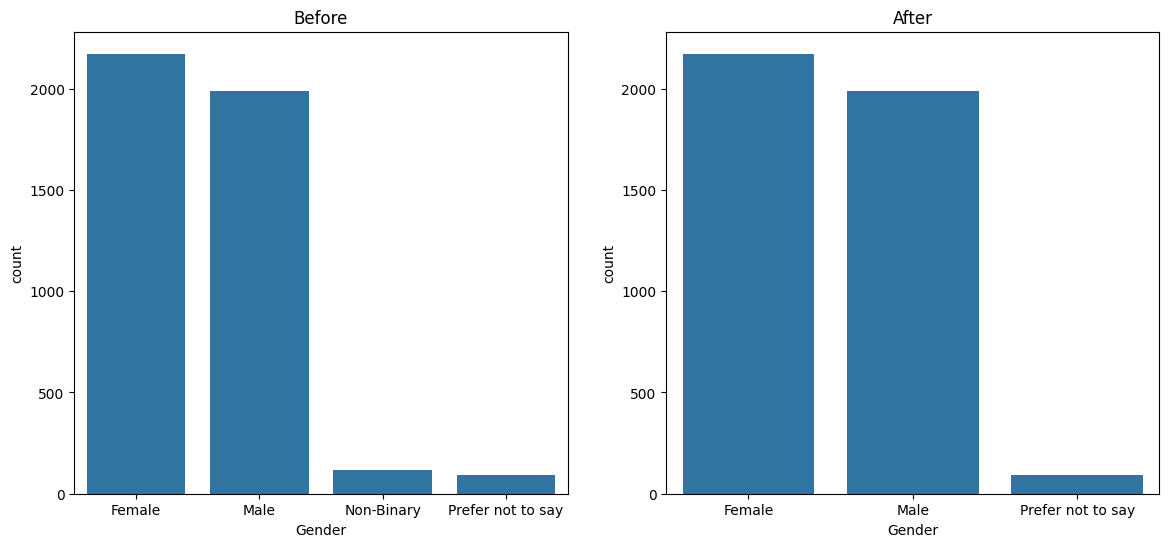

In [ ]:
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
sns.countplot(x=df["Gender"])
plt.title("Before")

df.drop(df[df["Gender"] == "Non-Binary"].index, inplace=True)#removing data since no category believed to exist

plt.subplot(1, 2, 2)
sns.countplot(x=df["Gender"])
plt.title("After")

a slight imbalance between Male and Female however we find that a greater Imbalance between "prefer not to say" to the rest

<Axes: xlabel='Academic_Level'>

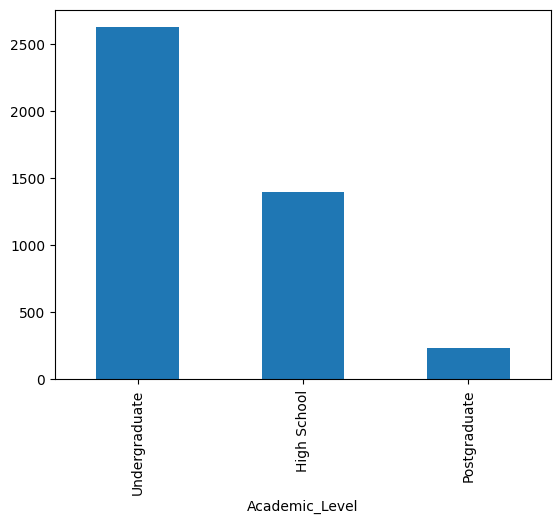

In [ ]:
df["Academic_Level"].value_counts().plot(kind="bar")

There is an imbalance in data. Where the most are UnderGraduate (this should be taken into conideration before utilizing Accuracy)

<Axes: xlabel='Age', ylabel='Count'>

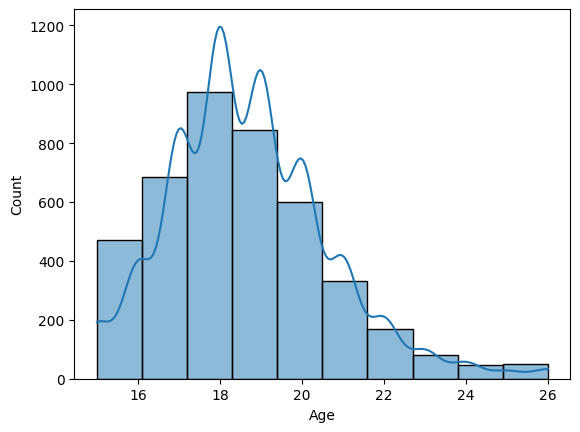

In [ ]:
sns.histplot(df["Age"] , kde = True, bins = 10)

In [ ]:
df["Age"].skew()

np.float64(0.6931057633616776)

Most of the students age range between 16 and 20. There is a slight skew to the right. overall a close enough balance.

<Axes: xlabel='Mental_Health_Index', ylabel='Count'>

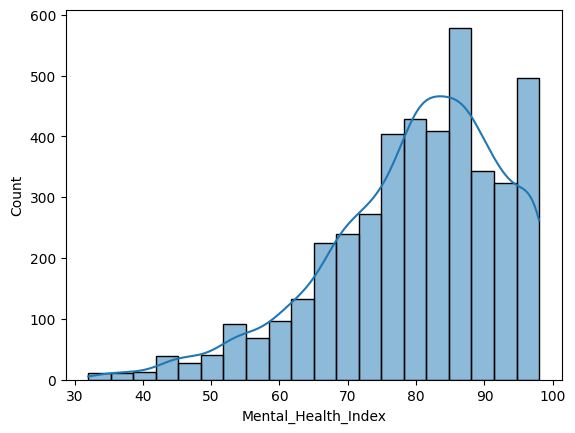

In [ ]:
sns.histplot(df["Mental_Health_Index"], kde=True, bins=20)

In [ ]:
df["Mental_Health_Index"].skew().round(2)

np.float64(-0.81)

there is a very slight of imbalance due to the curveture or skew of the data. the data is left skewed

<Axes: xlabel='Primary_Platform'>

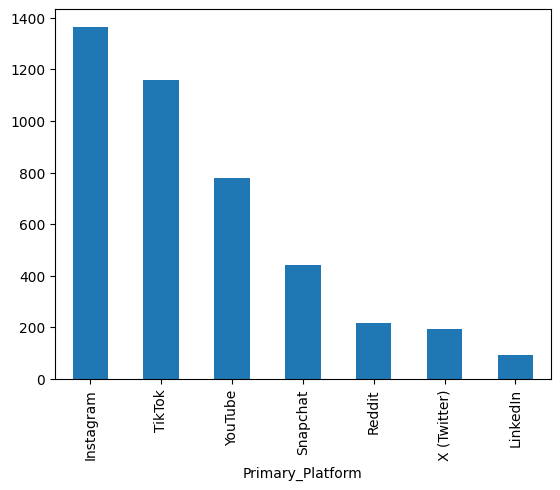

In [ ]:
df["Primary_Platform"].value_counts().plot(kind="bar")

The plot represents the mostly used platforms by users. Instagram is the most used out of all platforms while Linkedin is the least used one.

<Axes: xlabel='Daily_Usage_Hours', ylabel='Count'>

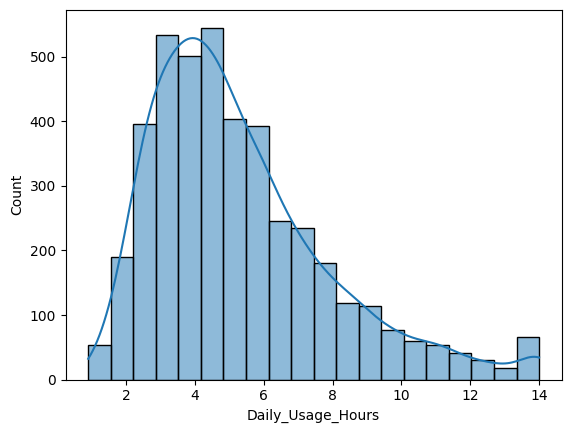

In [ ]:
sns.histplot(df["Daily_Usage_Hours"], kde=True, bins=20)

In [ ]:
df["Daily_Usage_Hours"].skew().round(2)

np.float64(1.14)

an imbalance of data with a skew of 1.14, indicates that the majority of daily usage are between 2-6 hours daily.

### Bivariante

<Axes: >

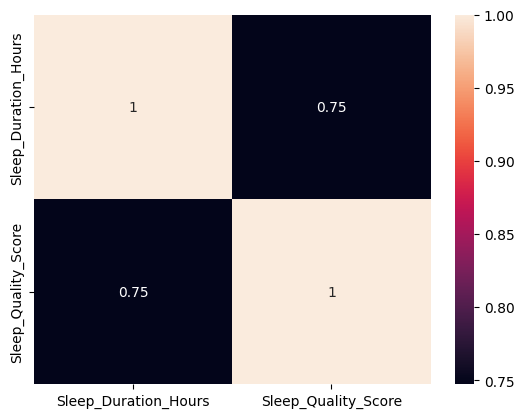

In [ ]:
sns.heatmap(df[["Sleep_Duration_Hours", "Sleep_Quality_Score"]].corr(), annot = True)

sleep quality score is derived from sleep Duration where the correlation between them is strong positive which is understandable

<Axes: xlabel='Academic_Level'>

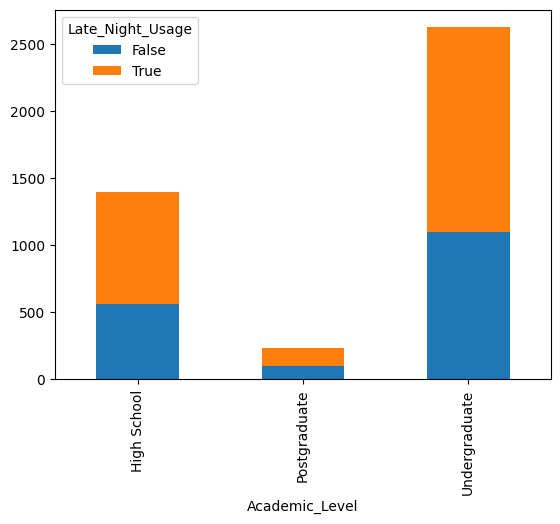

In [ ]:
(df.groupby("Academic_Level")["Late_Night_Usage"].value_counts().unstack()).plot(kind="bar",stacked=True)

undergraduates seem to have more usage during late nights compared to other Academic levels.

<Axes: xlabel='Academic_Level'>

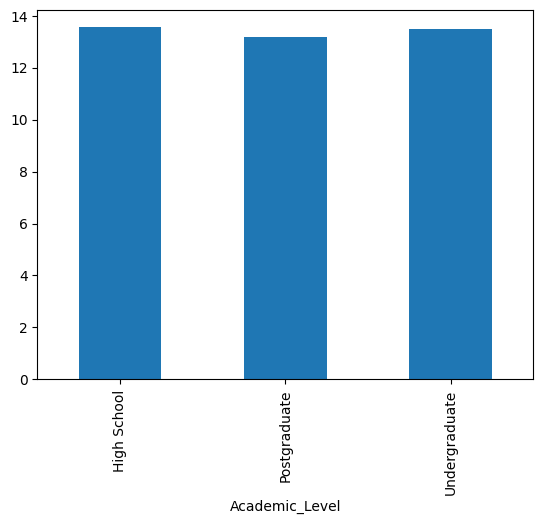

In [ ]:
df.groupby("Academic_Level")["Perceived_Stress_Score"].mean().plot(kind="bar")

we can extract that stress isnt categorized based on academic levels but its equalibrim which indicate that all have there own unique stress (requires searching other relations)

In [ ]:
df.groupby("Social_Comparison_Frequency")["Perceived_Stress_Score"].mean()

,Perceived_Stress_Score
Social_Comparison_Frequency,
Always,13.590985
Frequently,13.376701
Never,13.527559
Rarely,13.768156
Sometimes,13.438247


### The Study Of Usage and Mental Health

<Axes: xlabel='Sleep_Duration_Hours', ylabel='Perceived_Stress_Score'>

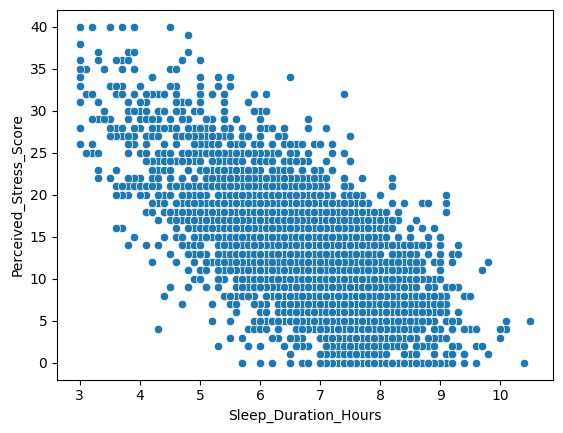

In [ ]:
sns.scatterplot(data=df,x="Sleep_Duration_Hours",y="Perceived_Stress_Score")

In [ ]:
df["Sleep_Duration_Hours"].corr(df["Perceived_Stress_Score"])

np.float64(-0.6588606986956969)

there is a somewhat strong negative correlation between Stress score and sleep duration. students that sleep less tend to have more stress levels


<Axes: xlabel='Sleep_Duration_Hours', ylabel='Daily_Usage_Hours'>

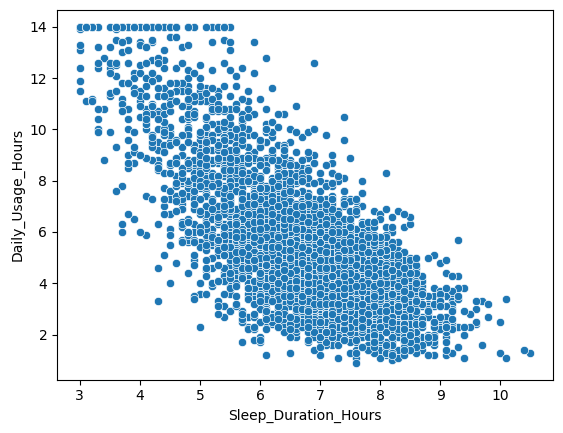

In [ ]:
sns.scatterplot(data=df,x="Sleep_Duration_Hours",y="Daily_Usage_Hours")

In [ ]:
df["Sleep_Duration_Hours"].corr(df["Daily_Usage_Hours"])

np.float64(-0.7150729404282694)

A strong negative correlation of 0.72 approximated, between usage and sleep. Meaning that more usage tends to lessen sleep. which indicates that our previous insight of stress levels hypering due to sleep is due to usage hours.(but requires further studying)

<Axes: xlabel='Daily_Usage_Hours', ylabel='Perceived_Stress_Score'>

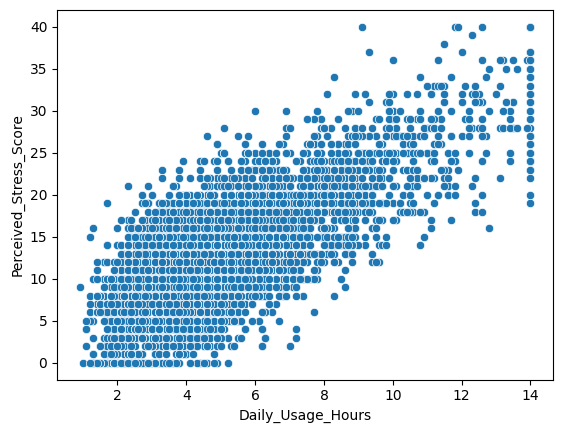

In [ ]:
sns.scatterplot(data=df,x="Daily_Usage_Hours",y="Perceived_Stress_Score")

In [ ]:
df["Daily_Usage_Hours"].corr(df["Perceived_Stress_Score"])

np.float64(0.7531471840144023)

A strong positive correlation of 0.75 between stress scores and Usage hours in a daily bases. which indicates that our hypothysis is true that the increase of stress is circled to the increase of social media hour usage.

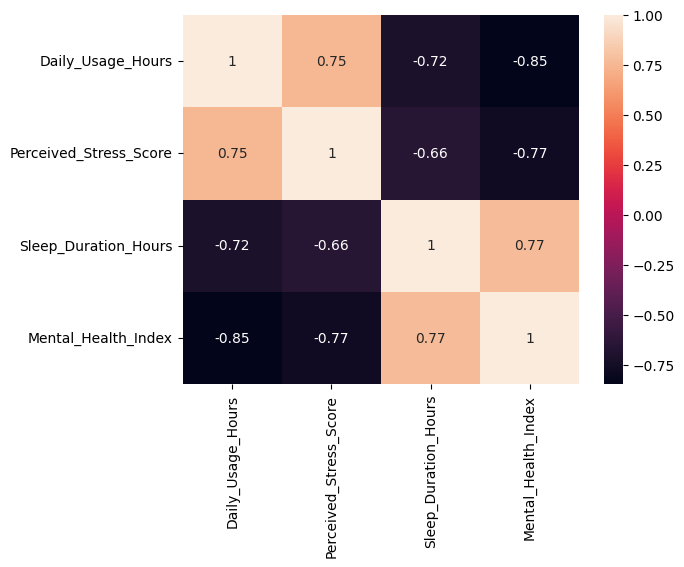

In [ ]:
cols = ["Daily_Usage_Hours","Perceived_Stress_Score","Sleep_Duration_Hours","Mental_Health_Index"]
corr = df[cols].corr()
sns.heatmap(corr, annot=True)
plt.show()

An increase of using social media daily leads to an increase in stress due to less sleep which affects your mental health

<Axes: >

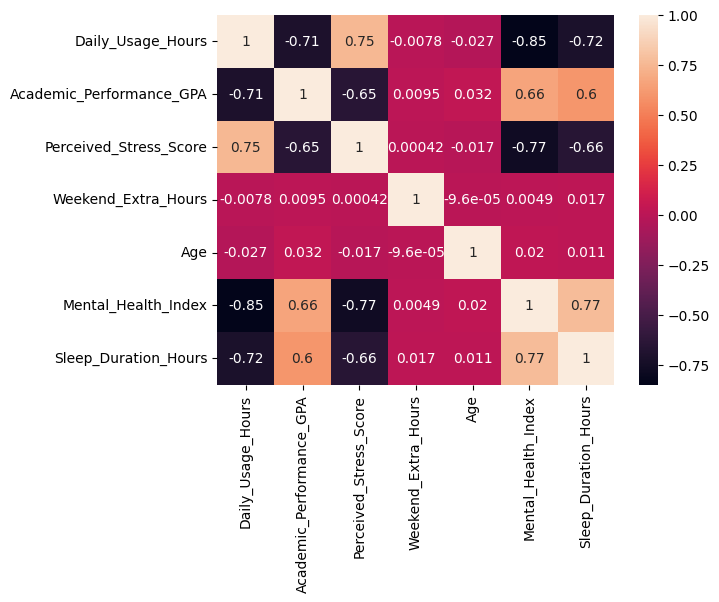

In [ ]:
sns.heatmap(df[["Daily_Usage_Hours", "Academic_Performance_GPA", "Perceived_Stress_Score", "Weekend_Extra_Hours", "Age", "Mental_Health_Index", "Sleep_Duration_Hours"]].corr(), annot = True)

### The Effects on Academic Performance

<Axes: xlabel='Academic_Performance_GPA', ylabel='Perceived_Stress_Score'>

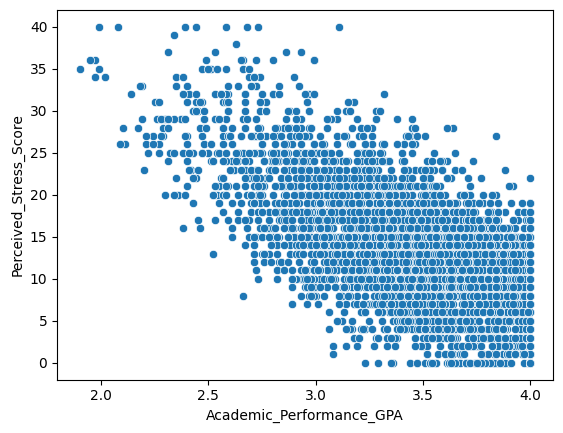

In [ ]:
sns.scatterplot(x="Academic_Performance_GPA", y="Perceived_Stress_Score", data=df)

A strong negative correlation between stress scores and Academic Performance. which indicates that with an increase of stress a decrease of Academic performance.(requires further studying)

<Axes: >

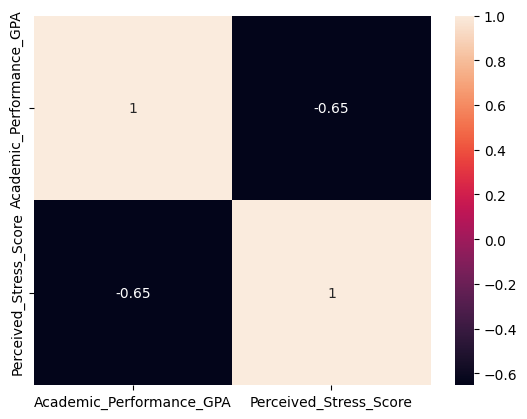

In [ ]:
sns.heatmap(df[["Academic_Performance_GPA", "Perceived_Stress_Score"]].corr(), annot=True)

In [ ]:
df["Perceived_Stress_Score"].corr(df["Academic_Performance_GPA"])

np.float64(-0.6529966521406649)

A somewhat strong negative correlation of 0.65 approximated between stress scores and Academic performance, meaning less results more stress which falls under the hypothysis of an increase of usage is an increase in stress which in turn is a decrease on performance

<Axes: xlabel='Academic_Performance_GPA', ylabel='Mental_Health_Index'>

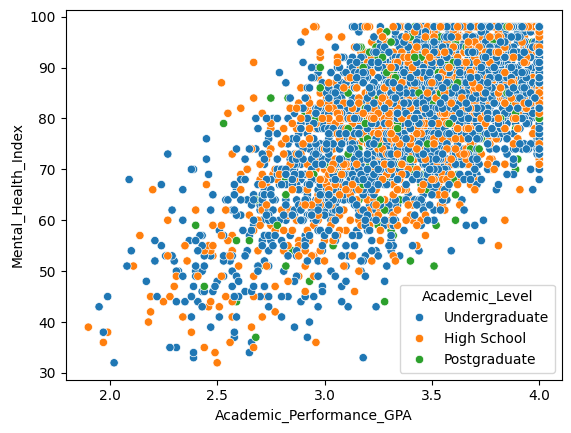

In [ ]:
sns.scatterplot(x="Academic_Performance_GPA", y="Mental_Health_Index", hue="Academic_Level" , data=df)

there is a somewhat strong positive correlation between Academic performance and mental health. students that are mentally healthy tend to act better in their academics

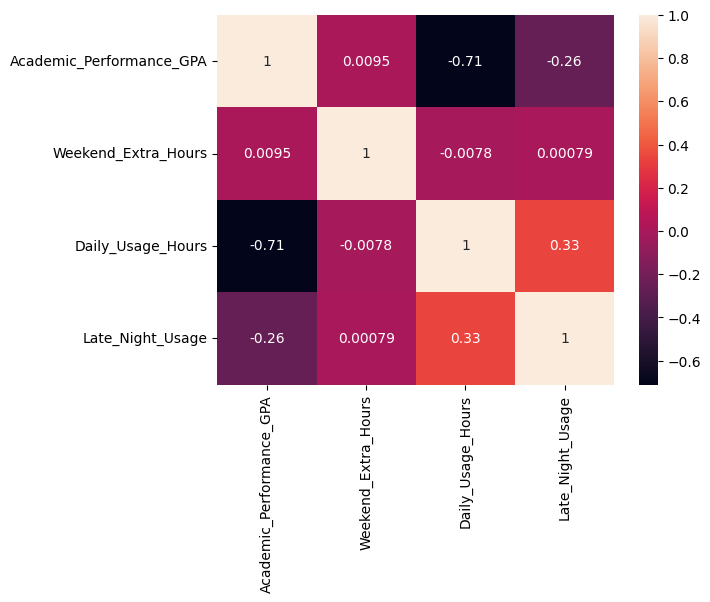

In [ ]:
cols = ["Academic_Performance_GPA","Weekend_Extra_Hours","Daily_Usage_Hours","Late_Night_Usage"]
corr = df[cols].corr()
sns.heatmap(corr, annot=True)
plt.show()

In [ ]:
df.columns


Index(['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Primary_Platform',
       'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Device_Type',
       'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Late_Night_Usage',
       'Social_Comparison_Frequency', 'Perceived_Stress_Score',
       'Mental_Health_Index', 'Academic_Performance_GPA', 'Overall_Impact'],
      dtype='object')

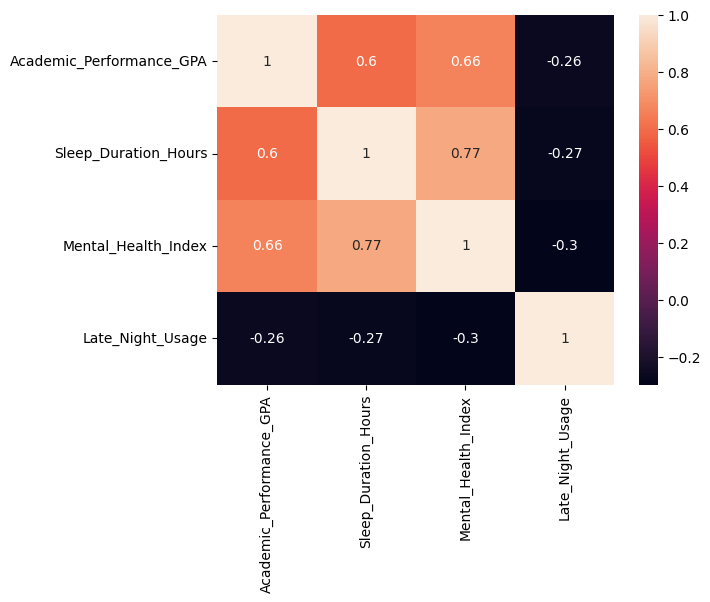

In [ ]:
cols = ["Academic_Performance_GPA",
        "Sleep_Duration_Hours",
        "Mental_Health_Index",
        "Late_Night_Usage"]

corr = df[cols].corr()

sns.heatmap(corr, annot=True)
plt.show()

Academic Performance increases with the increase of sleep duration and mental health which suggests a positive correlations

### Checking for any Relations

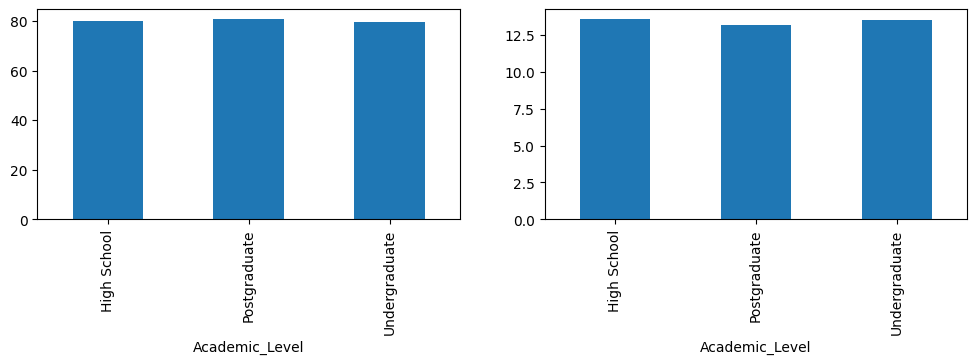

In [ ]:
plt.figure(figsize=(12, 6))

plt.subplot(2, 2, 1)
df.groupby("Academic_Level")["Mental_Health_Index"].mean().plot(kind="bar")
plt.subplot(2, 2, 2)
df.groupby("Academic_Level")["Perceived_Stress_Score"].mean().plot(kind="bar")
plt.show()

as perceived stress & mental health scores dont discriminate between different academic level, which indicates that its a big factor on Students Academics

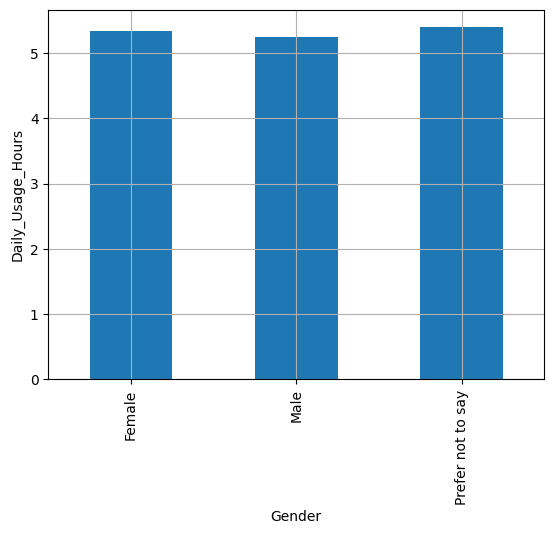

In [ ]:
(df.groupby("Gender")["Daily_Usage_Hours"].mean()).plot(kind="bar")
plt.ylabel("Daily_Usage_Hours")
plt.grid()

Usage has no affection on gender . they are balanced interms of usage

Text(0, 0.5, 'Daily_Usage_Hours')

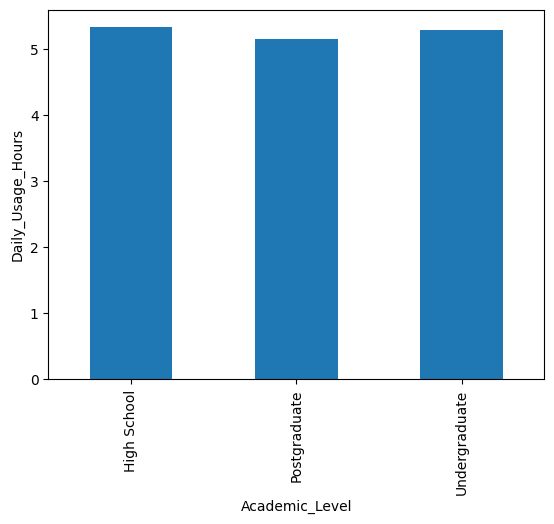

In [ ]:
(df.groupby("Academic_Level")["Daily_Usage_Hours"].mean()).plot(kind="bar")
plt.ylabel("Daily_Usage_Hours")

similar estimation as Genders plot

# Modeling

### Assigning Target & Features


In [ ]:
model_df = df.copy()

model_df["Late_Night_Usage"] = model_df["Late_Night_Usage"].astype(int)   #boolean

#X=pd.get_dummies(df,["Daily_Usage_Hours","Perceived_Stress_Score","Sleep_Duration_Hours",])
X = model_df.drop(["Mental_Health_Index","Academic_Performance_GPA","Overall_Impact","Student_ID", "Sleep_Quality_Score"], axis=1)
#droping "Mental_Health_Index","Academic_Performance_GPA", since they are leakage data of "Overall_Impact"
#reasons for droping Sleep_Quality is because its a redundants of Sleep Duration
#dropped Student_ID since one hot encoding or any encoding seperates them (note it wont affect the model if dropped)
y_labels = model_df["Overall_Impact"]

le = LabelEncoder()
y = le.fit_transform(y_labels)

print("Classes:", dict(zip(le.classes_, range(len(le.classes_)))))


Classes: {'Beneficial': 0, 'Negative': 1, 'Neutral': 2}


In [ ]:
X

,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score
0,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,1,Always,20.0
1,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,1,Sometimes,17.0
2,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,Frequently,18.0
3,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,1,Sometimes,15.0
4,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,1,Never,16.0
...,...,...,...,...,...,...,...,...,...,...,...
4495,16,Male,High School,YouTube,5.8,1.2,Smartphone,7.8,1,Sometimes,11.0
4496,19,Female,Undergraduate,LinkedIn,3.8,3.0,Smartphone,6.6,0,Frequently,9.0
4497,19,Male,Undergraduate,Instagram,7.7,1.1,Smartphone,6.0,1,Frequently,13.0
4498,16,Male,High School,LinkedIn,4.6,3.3,Laptop/PC,7.1,0,Sometimes,22.0


In [ ]:
X= pd.get_dummies(X,drop_first=True)

In [ ]:
X

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Late_Night_Usage,Perceived_Stress_Score,Gender_Male,Gender_Prefer not to say,Academic_Level_Postgraduate,Academic_Level_Undergraduate,...,Primary_Platform_Snapchat,Primary_Platform_TikTok,Primary_Platform_X (Twitter),Primary_Platform_YouTube,Device_Type_Smartphone,Device_Type_Tablet,Social_Comparison_Frequency_Frequently,Social_Comparison_Frequency_Never,Social_Comparison_Frequency_Rarely,Social_Comparison_Frequency_Sometimes
0,19,7.5,1.5,5.9,1,20.0,False,False,False,True,...,True,False,False,False,True,False,False,False,False,False
1,19,4.6,1.3,7.9,1,17.0,False,False,False,True,...,False,False,False,False,True,False,False,False,False,True
2,17,10.9,1.7,5.2,1,18.0,False,False,False,False,...,False,True,False,False,True,False,True,False,False,False
3,16,6.0,2.3,7.6,1,15.0,False,False,False,False,...,False,False,False,True,False,True,False,False,False,True
4,17,3.3,2.6,7.6,1,16.0,True,False,False,False,...,False,False,False,False,True,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4495,16,5.8,1.2,7.8,1,11.0,True,False,False,False,...,False,False,False,True,True,False,False,False,False,True
4496,19,3.8,3.0,6.6,0,9.0,False,False,False,True,...,False,False,False,False,True,False,True,False,False,False
4497,19,7.7,1.1,6.0,1,13.0,True,False,False,True,...,False,False,False,False,True,False,True,False,False,False
4498,16,4.6,3.3,7.1,0,22.0,True,False,False,False,...,False,False,False,False,False,False,False,False,False,True


## Target distribution

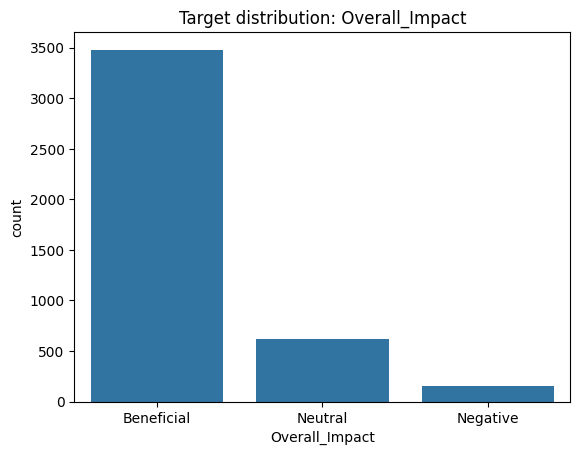

In [ ]:
sns.countplot(x=y_labels, order=y_labels.value_counts().index)
plt.title("Target distribution: Overall_Impact")
plt.show()

## Train / Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

## Model Training: SVM

In [ ]:
svm1 = SVC(kernel="rbf")
scores1 = cross_val_score(svm1, X_train, y_train, cv=5, scoring="f1_weighted")
print("Without scaling:", scores1.mean())

svm2 = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="rbf"))])
scores2 = cross_val_score(svm2, X_train, y_train, cv=5, scoring="f1_weighted")
print("With scaling:", scores2.mean())

Without scaling: 0.9478155084351432
With scaling: 0.9307143267836124


Accuracy: 0.9247943595769683
Precision: 0.9198809961410768
Recall: 0.9247943595769683
F1: 0.9209662311158684
              precision    recall  f1-score   support

  Beneficial       0.95      0.98      0.97       697
    Negative       0.78      0.58      0.67        31
     Neutral       0.78      0.67      0.72       123

    accuracy                           0.92       851
   macro avg       0.84      0.75      0.79       851
weighted avg       0.92      0.92      0.92       851



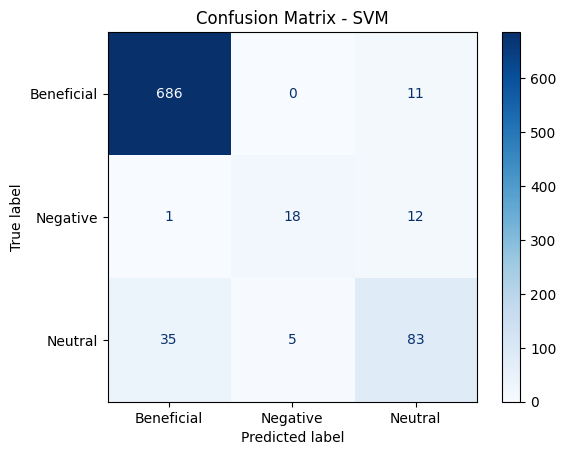

In [ ]:
svm = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="rbf"))])
svm.fit(X_train, y_train)
y_pred = svm.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="weighted"))
print("Recall:", recall_score(y_test, y_pred, average="weighted"))
print("F1:", f1_score(y_test, y_pred, average="weighted"))
print(classification_report(y_test, y_pred, target_names=le.classes_))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_, cmap="Blues")
plt.title("Confusion Matrix - SVM")
plt.show()

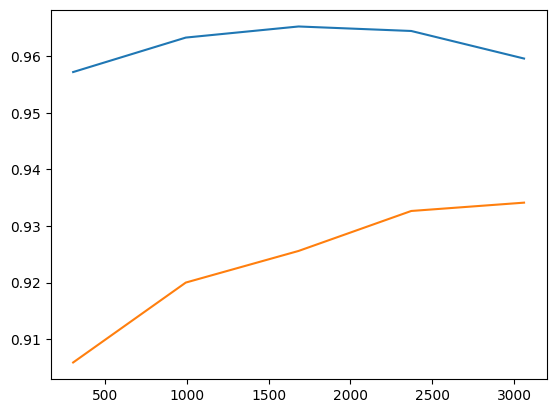

In [ ]:
train_sizes, train_scores, val_scores = learning_curve(
    svm,
    X_train,
    y_train,
    cv=10
)

plt.plot(train_sizes, train_scores.mean(axis = 1))
plt.plot(train_sizes, val_scores.mean(axis = 1))

linear : 0.9454322030258971
rbf : 0.9307143267836124
poly : 0.91471668994713
sigmoid : 0.934624794574286


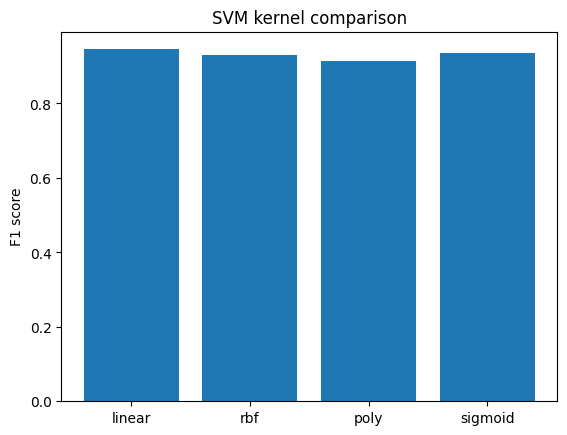

In [ ]:
kernels = ["linear", "rbf", "poly", "sigmoid"]
results = []

for k in kernels:
    model = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel=k))])
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="f1_weighted")
    results.append(scores.mean())
    print(k, ":", scores.mean())

plt.bar(kernels, results)
plt.ylabel("F1 score")
plt.title("SVM kernel comparison")
plt.show()

#Linear kernel performed slightly better than other kernels.

# Tuning SVM Model
After comparing four different types of kernels, the linear kernel outperformed the other kernels with F1 score = 95%  

Accuracy: 0.9494712103407755
Precision: 0.9486925562828289
Recall: 0.9494712103407755
F1: 0.9490205482767115
              precision    recall  f1-score   support

  Beneficial       0.97      0.98      0.97       697
    Negative       0.87      0.87      0.87        31
     Neutral       0.84      0.80      0.82       123

    accuracy                           0.95       851
   macro avg       0.89      0.88      0.89       851
weighted avg       0.95      0.95      0.95       851



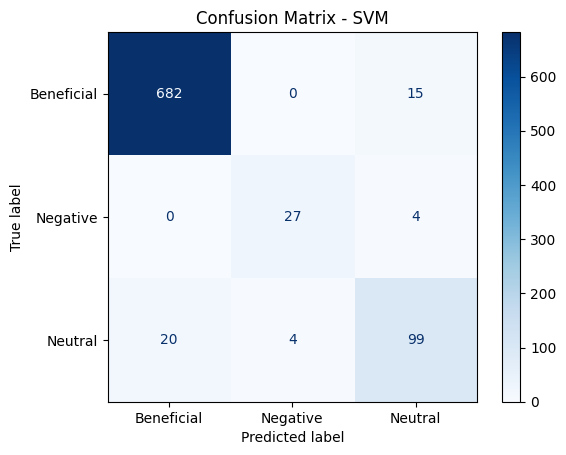

In [ ]:
tuned_svm = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="linear"))])


tuned_svm.fit(X_train, y_train)
tuned_y_pred = tuned_svm.predict(X_test)

print("Accuracy:", accuracy_score(y_test, tuned_y_pred))
print("Precision:", precision_score(y_test, tuned_y_pred, average="weighted"))
print("Recall:", recall_score(y_test, tuned_y_pred, average="weighted"))
print("F1:", f1_score(y_test, tuned_y_pred, average="weighted"))
print(classification_report(y_test, tuned_y_pred, target_names=le.classes_))


"""
cv = StratifiedKFold(n_splits = 5, shuffle=True , random_state=42)

f1_tuned_score = cross_val_score(tuned_svm, X_train, y_train, cv=5, scoring="f1_weighted")
acc_tuned_score = cross_val_score(tuned_svm, X_train, y_train, cv=5, scoring="accuracy")
precision_tuned_score = cross_val_score(tuned_svm, X_train, y_train, cv=5, scoring="precision_weighted")
recall_tuned_score = cross_val_score(tuned_svm, X_train, y_train, cv=5, scoring="recall_weighted")



print(f"Accuracy: {acc_tuned_score.mean()}")
print(f"F1-score: {f1_tuned_score.mean()}")
print(f"Precision: {precision_tuned_score.mean()}")
print(f"Recall: {recall_tuned_score.mean()}")
"""

ConfusionMatrixDisplay.from_predictions(y_test, tuned_y_pred, display_labels=le.classes_, cmap="Blues")
plt.title("Confusion Matrix - SVM")
plt.show()

# Logistic Regression Model for comparison

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Accuracy: 0.936545240893067
Precision: 0.9355271207760145
Recall: 0.936545240893067
F1: 0.9356153344865125
              precision    recall  f1-score   support

  Beneficial       0.97      0.98      0.97       697
    Negative       0.71      0.81      0.76        31
     Neutral       0.81      0.73      0.77       123

    accuracy                           0.94       851
   macro avg       0.83      0.84      0.83       851
weighted avg       0.94      0.94      0.94       851



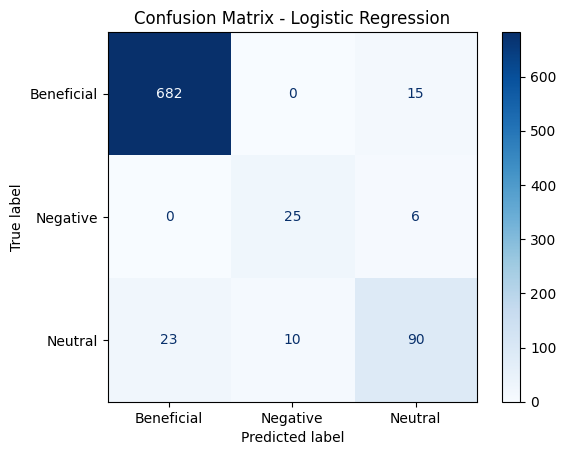

In [ ]:
#compare_model = make_pipeline(StandardScaler(), LogisticRegression())
compare_model = LogisticRegression()
compare_model.fit(X_train, y_train )

y_compare = compare_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_compare))
print("Precision:", precision_score(y_test, y_compare, average="weighted"))
print("Recall:", recall_score(y_test, y_compare, average="weighted"))
print("F1:", f1_score(y_test, y_compare, average="weighted"))
print(classification_report(y_test, y_compare, target_names=le.classes_))

ConfusionMatrixDisplay.from_predictions(y_test, y_compare, display_labels=le.classes_, cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

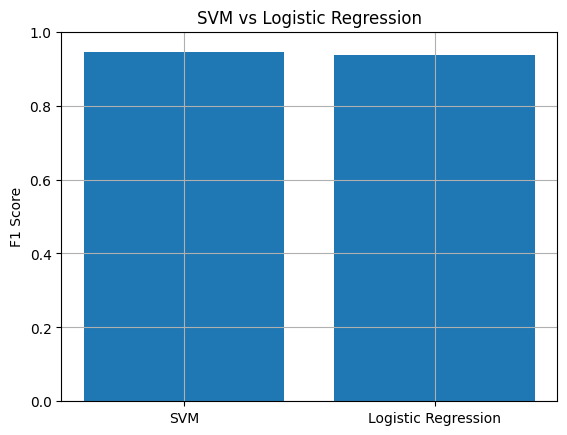

In [ ]:
models = ["SVM", "Logistic Regression"]
F1_scores = [acc_tuned_score.mean(), f1_score(y_test, y_compare, average="weighted")]
plt.bar(models, F1_scores)
plt.title("SVM vs Logistic Regression")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.grid()
plt.show()